<a href="https://colab.research.google.com/github/swetha682/imagined-speech-eeg/blob/main/02_EEG_Signal_Characterization_and_Representation_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import glob
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import signal, stats
from scipy.io import loadmat
from scipy.stats import skew, kurtosis
from google.colab import drive

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "experiment_outputs",
    "Signal_Characterization"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Output directory:", OUTPUT_DIR)

assert os.path.exists(DATASET_DIR), "Dataset folder not found!"


Mounted at /content/drive
Project directory: /content/drive/MyDrive/Imagined_Speech_EEG_Project
Dataset directory: /content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset
Output directory: /content/drive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/Signal_Characterization


In [ ]:

mat_files = glob.glob(
    os.path.join(DATASET_DIR, "**", "*.mat"),
    recursive=True
)

print("Total MATLAB files found:", len(mat_files))

for file in sorted(mat_files)[:20]:
    print(file)


Total MATLAB files found: 45
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample01.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample02.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample03.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample04.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample05.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample06.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample07.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample08.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample09.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample10.mat
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Test set/Data_Sample11.mat
/content/drive/MyDrive/Im

In [ ]:

if len(mat_files) == 0:
    raise FileNotFoundError("No .mat files found in dataset folder.")

sample_file = mat_files[0]

print("Inspecting:", sample_file)

mat_data = loadmat(sample_file)

for key, value in mat_data.items():
    if not key.startswith("__"):
        print(
            "Variable:", key,
            "| Type:", type(value),
            "| Shape:", getattr(value, "shape", None),
            "| Dtype:", getattr(value, "dtype", None)
        )


Inspecting: /content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample01.mat
Variable: epo_validation | Type: <class 'numpy.ndarray'> | Shape: (1, 1) | Dtype: [('clab', 'O'), ('fs', 'O'), ('title', 'O'), ('file', 'O'), ('x', 'O'), ('y', 'O'), ('t', 'O'), ('className', 'O')]
Variable: mnt | Type: <class 'numpy.ndarray'> | Shape: (1, 1) | Dtype: [('x', 'O'), ('y', 'O'), ('pos_3d', 'O'), ('clab', 'O')]


In [ ]:

# Extract the MATLAB structure
epo = mat_data["epo_validation"][0, 0]

print("===== EPO VALIDATION STRUCTURE =====")

for field in epo.dtype.names:

    value = epo[field]

    print(f"\nField: {field}")
    print("Shape:", value.shape)
    print("Data type:", value.dtype)

    # Display contents safely
    if value.size <= 20:
        print("Content:", value)
    else:
        print("Content preview:", value.flatten()[:10])


===== EPO VALIDATION STRUCTURE =====

Field: clab
Shape: (1, 64)
Data type: object
Content preview: [array(['Fp1'], dtype='<U3') array(['Fp2'], dtype='<U3')
 array(['F7'], dtype='<U2') array(['F3'], dtype='<U2')
 array(['Fz'], dtype='<U2') array(['F4'], dtype='<U2')
 array(['F8'], dtype='<U2') array(['FC5'], dtype='<U3')
 array(['FC1'], dtype='<U3') array(['FC2'], dtype='<U3')]

Field: fs
Shape: (1, 1)
Data type: uint16
Content: [[256]]

Field: title
Shape: (1,)
Data type: <U4
Content: ['sub1']

Field: file
Shape: (1,)
Data type: <U4
Content: ['sub1']

Field: x
Shape: (795, 64, 50)
Data type: float64
Content preview: [ -5.5173932   49.81607913  28.97323027 205.51427916 -17.90904486
  24.73238852  84.65383516  16.20074951   3.54551257  45.65144274]

Field: y
Shape: (5, 50)
Data type: uint8
Content preview: [0 0 0 0 0 0 0 0 0 0]

Field: t
Shape: (1, 795)
Data type: float64
Content preview: [-500.      -496.09375 -492.1875  -488.28125 -484.375   -480.46875
 -476.5625  -472.65625 -468.75  

In [ ]:

def extract_field(structure, field):
    value = structure[field]

    # Unwrap nested single-element object arrays
    while isinstance(value, np.ndarray) and value.dtype == object and value.size == 1:
        value = value.flat[0]

    return value

eeg = extract_field(epo, "x")
fs = extract_field(epo, "fs")
labels = extract_field(epo, "y")
channels = extract_field(epo, "clab")
class_names = extract_field(epo, "className")

print("EEG shape:", np.shape(eeg))
print("Sampling frequency:", fs)
print("Labels shape:", np.shape(labels))
print("Channels shape:", np.shape(channels))
print("Class names shape:", np.shape(class_names))

print("\nChannel preview:")
print(np.array(channels).flatten()[:10])

print("\nClass names:")
print(class_names)


EEG shape: (795, 64, 50)
Sampling frequency: [[256]]
Labels shape: (5, 50)
Channels shape: (1, 64)
Class names shape: (1, 5)

Channel preview:
[array(['Fp1'], dtype='<U3') array(['Fp2'], dtype='<U3')
 array(['F7'], dtype='<U2') array(['F3'], dtype='<U2')
 array(['Fz'], dtype='<U2') array(['F4'], dtype='<U2')
 array(['F8'], dtype='<U2') array(['FC5'], dtype='<U3')
 array(['FC1'], dtype='<U3') array(['FC2'], dtype='<U3')]

Class names:
[[array(['Hello'], dtype='<U5') array(['Helpme'], dtype='<U6')
  array(['Stop'], dtype='<U4') array(['Thankyou'], dtype='<U8')
  array(['Yes'], dtype='<U3')]]


In [ ]:

print("Label array shape:", np.shape(labels))
print("Label contents:")
print(labels)

print("\nUnique label values and counts:")
print(np.unique(np.asarray(labels), return_counts=True))


Label array shape: (5, 50)
Label contents:
[[0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1
  0 0 0 1 0 0 1 0 0 0 1 1 0 0]
 [0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  1 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 1 1 1 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0
  0 0 0 0 0 0 0 1 0 0 0 0 1 0]
 [1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 1 0 1 0 0 0 0
  0 0 0 0 0 0 0 0 0 1 0 0 0 1]
 [0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0
  0 1 1 0 1 0 0 0 1 0 0 0 0 0]]

Unique label values and counts:
(array([0, 1], dtype=uint8), array([200,  50]))


In [ ]:

# Convert one-hot labels into integer class IDs
Y = np.asarray(labels)

# Each trial should have exactly one active class
column_sums = np.sum(Y, axis=0)

print("One-hot encoding check:")
print("Unique column sums:", np.unique(column_sums))
print("Every trial has exactly one class:", np.all(column_sums == 1))

# Convert each trial to its class index
class_ids = np.argmax(Y, axis=0)

# Extract readable class names
class_names_clean = [
    np.asarray(item).flatten()[0]
    for item in class_names.flatten()
]

print("\nClass mapping:")
for i, name in enumerate(class_names_clean):
    print(i, "=", name)

print("\nTrial distribution:")
for i, name in enumerate(class_names_clean):
    print(f"{name}: {np.sum(class_ids == i)} trials")


One-hot encoding check:
Unique column sums: [1]
Every trial has exactly one class: True

Class mapping:
0 = Hello
1 = Helpme
2 = Stop
3 = Thankyou
4 = Yes

Trial distribution:
Hello: 10 trials
Helpme: 10 trials
Stop: 10 trials
Thankyou: 10 trials
Yes: 10 trials


Sampling frequency: 256.0 Hz
Number of time samples: 795
Start time: -500.0 ms
End time: 2601.5625 ms
Time interval: 3.90625 ms
Duration: 3.1015625 seconds


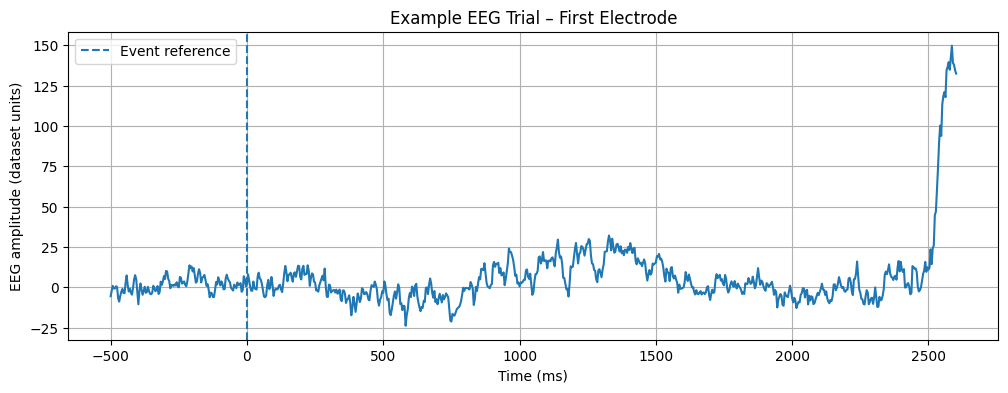

In [ ]:

time_ms = np.asarray(
    extract_field(epo, "t")
).flatten()

sampling_rate = float(np.asarray(fs).squeeze())

print("Sampling frequency:", sampling_rate, "Hz")
print("Number of time samples:", len(time_ms))
print("Start time:", time_ms[0], "ms")
print("End time:", time_ms[-1], "ms")
print("Time interval:", np.mean(np.diff(time_ms)), "ms")

print(
    "Duration:",
    (time_ms[-1] - time_ms[0]) / 1000,
    "seconds"
)

plt.figure(figsize=(12, 4))
plt.plot(time_ms, eeg[:, 0, 0])
plt.axvline(0, linestyle="--", label="Event reference")
plt.xlabel("Time (ms)")
plt.ylabel("EEG amplitude (dataset units)")
plt.title("Example EEG Trial – First Electrode")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

channel_names = [
    np.asarray(item).flatten()[0]
    for item in channels.flatten()
]

print("Total electrodes:", len(channel_names))

for i, name in enumerate(channel_names):
    print(f"{i:02d}: {name}")


Total electrodes: 64
00: Fp1
01: Fp2
02: F7
03: F3
04: Fz
05: F4
06: F8
07: FC5
08: FC1
09: FC2
10: FC6
11: T7
12: C3
13: Cz
14: C4
15: T8
16: TP9
17: CP5
18: CP1
19: CP2
20: CP6
21: TP10
22: P7
23: P3
24: Pz
25: P4
26: P8
27: PO9
28: O1
29: Oz
30: O2
31: PO10
32: AF7
33: AF3
34: AF4
35: AF8
36: F5
37: F1
38: F2
39: F6
40: FT9
41: FT7
42: FC3
43: FC4
44: FT8
45: FT10
46: C5
47: C1
48: C2
49: C6
50: TP7
51: CP3
52: CPz
53: CP4
54: TP8
55: P5
56: P1
57: P2
58: P6
59: PO7
60: PO3
61: POz
62: PO4
63: PO8


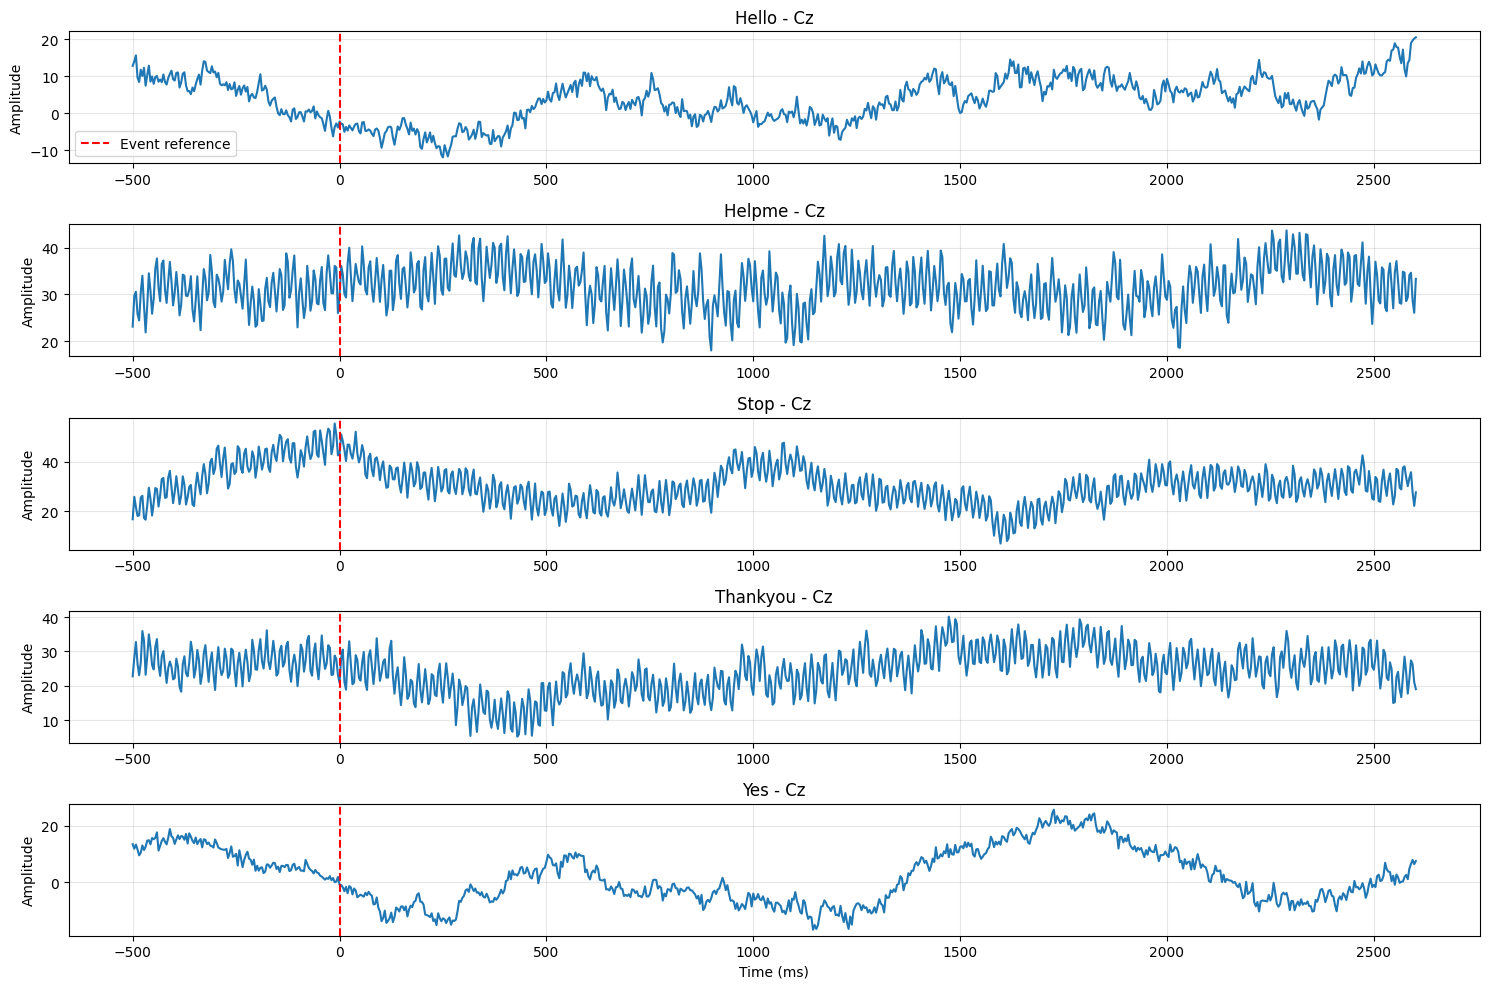

In [ ]:
# Select Cz for an initial visual inspection only
electrode_name = "Cz"
electrode_index = channel_names.index(electrode_name)

plt.figure(figsize=(15, 10))

for class_id, class_name in enumerate(class_names_clean):
    # Find the first trial belonging to this class
    trial_index = np.where(class_ids == class_id)[0][0]

    # Extract EEG from Cz for that trial
    eeg_trial = eeg[:, electrode_index, trial_index]

    plt.subplot(5, 1, class_id + 1)
    plt.plot(time_ms, eeg_trial)
    plt.axvline(0, color="red", linestyle="--", label="Event reference")
    plt.title(f"{class_name} - {electrode_name}")
    plt.ylabel("Amplitude")
    plt.grid(True, alpha=0.3)

    if class_id == 0:
        plt.legend()

plt.xlabel("Time (ms)")
plt.tight_layout()
plt.show()

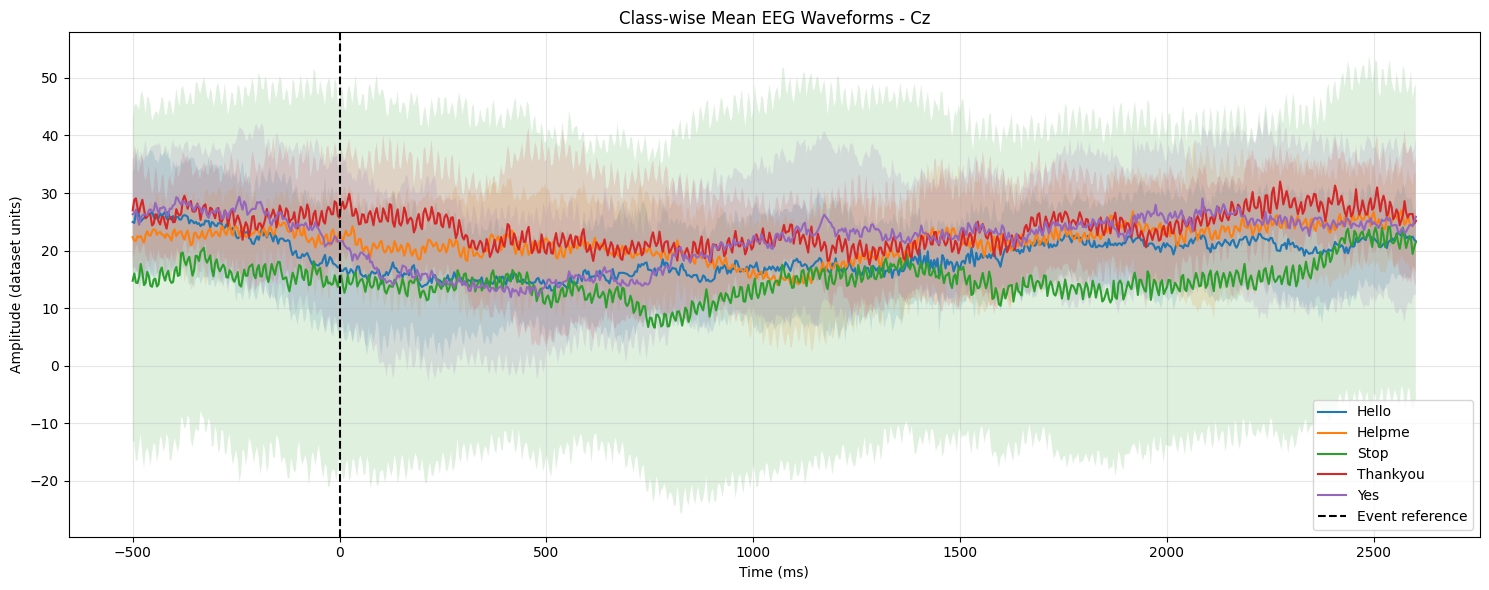

In [ ]:
plt.figure(figsize=(15, 6))

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    # Shape: time samples x trials
    class_data = eeg[:, electrode_index, selected_trials]

    mean_signal = np.mean(class_data, axis=1)
    std_signal = np.std(class_data, axis=1)

    plt.plot(time_ms, mean_signal, label=class_name)
    plt.fill_between(
        time_ms,
        mean_signal - std_signal,
        mean_signal + std_signal,
        alpha=0.15
    )

plt.axvline(0, color="black", linestyle="--", label="Event reference")
plt.title(f"Class-wise Mean EEG Waveforms - {electrode_name}")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Baseline amplitude statistics at Cz
Mean: 22.817798211455703
Standard deviation: 16.07433854588021
Minimum: -72.56972968188498
Maximum: 44.38904618318311


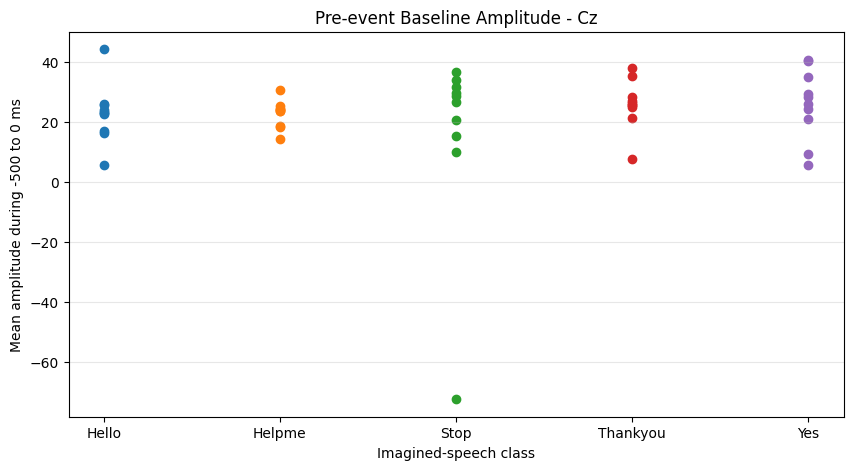

In [ ]:
# Cell 13: Baseline analysis at Cz

baseline_mask = (time_ms >= -500) & (time_ms < 0)

baseline_values = []
baseline_corrected_data = eeg[:, electrode_index, :].copy()

for trial_index in range(eeg.shape[2]):

    trial = eeg[:, electrode_index, trial_index]

    # Mean amplitude during the pre-event period
    baseline_mean = np.mean(trial[baseline_mask])
    baseline_values.append(baseline_mean)

    # Baseline correction for inspection only
    baseline_corrected_data[:, trial_index] = trial - baseline_mean

baseline_values = np.array(baseline_values)

print("Baseline amplitude statistics at", electrode_name)
print("Mean:", np.mean(baseline_values))
print("Standard deviation:", np.std(baseline_values))
print("Minimum:", np.min(baseline_values))
print("Maximum:", np.max(baseline_values))

# Compare baseline values across classes
plt.figure(figsize=(10, 5))

for class_id, class_name in enumerate(class_names_clean):
    selected = np.where(class_ids == class_id)[0]
    plt.scatter(
        [class_name] * len(selected),
        baseline_values[selected],
        label=class_name
    )

plt.title(f"Pre-event Baseline Amplitude - {electrode_name}")
plt.xlabel("Imagined-speech class")
plt.ylabel("Mean amplitude during -500 to 0 ms")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
print("BASELINE ANALYSIS - Cz")
print("=" * 55)

baseline_df = pd.DataFrame({
    "Class": [class_names_clean[i] for i in class_ids],
    "Baseline_Mean": baseline_values
})

print("\nClass-wise baseline statistics:")
print(
    baseline_df.groupby("Class")["Baseline_Mean"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
    .to_string()
)

BASELINE ANALYSIS - Cz

Class-wise baseline statistics:
             mean      std      min      max
Class                                       
Hello     22.9032   9.7595   5.5551  44.3890
Helpme    22.8849   4.5721  14.3513  30.8657
Stop      16.1410  32.2634 -72.5697  36.6848
Thankyou  26.0926   8.1860   7.6338  38.1331
Yes       26.0673  11.7552   5.7087  40.7310


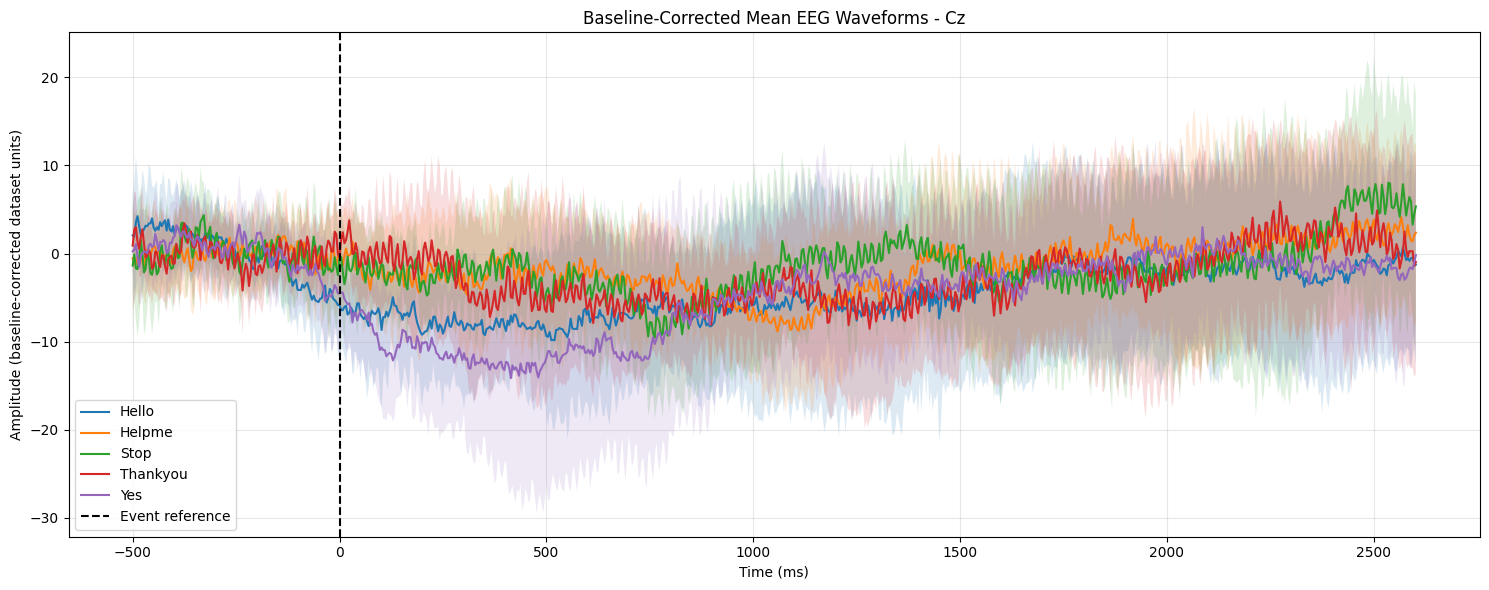

In [ ]:
# Display the same class-wise mean waveforms after baseline correction

plt.figure(figsize=(15, 6))

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    class_data = baseline_corrected_data[:, selected_trials]

    mean_signal = np.mean(class_data, axis=1)
    std_signal = np.std(class_data, axis=1)

    plt.plot(time_ms, mean_signal, label=class_name)
    plt.fill_between(
        time_ms,
        mean_signal - std_signal,
        mean_signal + std_signal,
        alpha=0.15
    )

plt.axvline(0, color="black", linestyle="--", label="Event reference")
plt.title(f"Baseline-Corrected Mean EEG Waveforms - {electrode_name}")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (baseline-corrected dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 15: Calculate PSD for every trial at Cz

frequency_values = None
psd_trials = []

for trial_index in range(eeg.shape[2]):

    trial = eeg[:, electrode_index, trial_index]

    frequencies, psd = signal.welch(
        trial,
        fs=sampling_rate,
        window="hann",
        nperseg=256,
        noverlap=128,
        detrend="constant",
        scaling="density"
    )

    psd_trials.append(psd)

psd_trials = np.array(psd_trials)
frequency_values = frequencies

print("PSD array shape:", psd_trials.shape)
print("Frequency resolution:", frequencies[1] - frequencies[0], "Hz")

PSD array shape: (50, 129)
Frequency resolution: 1.0 Hz


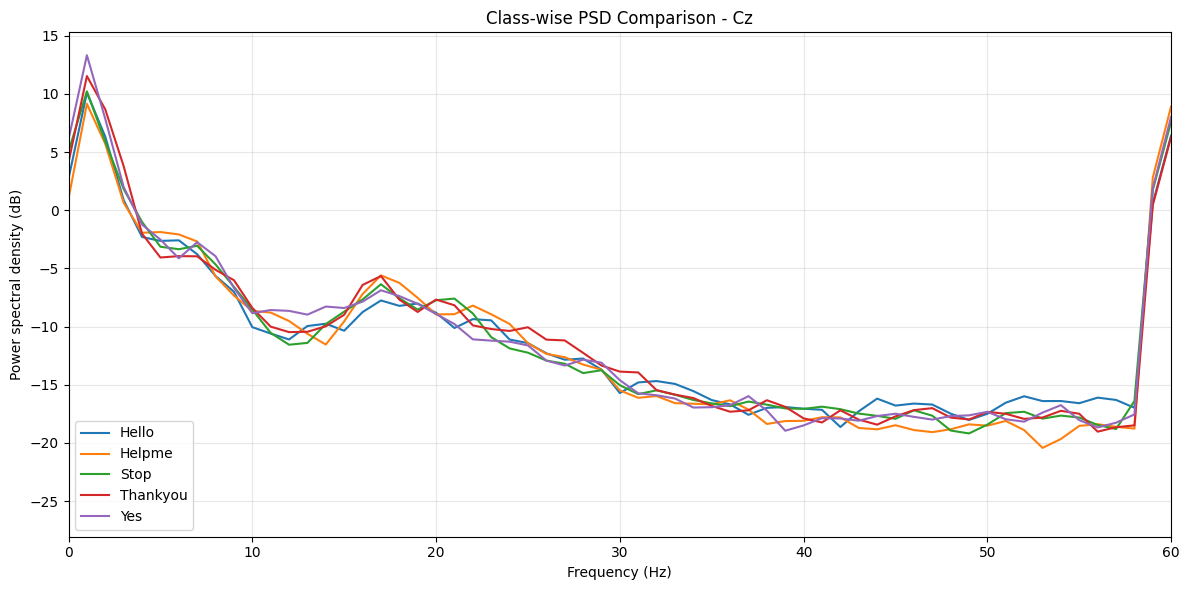

In [ ]:
plt.figure(figsize=(12, 6))

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    class_psd = psd_trials[selected_trials, :]

    mean_psd = np.mean(class_psd, axis=0)

    plt.plot(
        frequency_values,
        10 * np.log10(mean_psd + 1e-12),
        label=class_name
    )

plt.xlim(0, 60)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density (dB)")
plt.title(f"Class-wise PSD Comparison - {electrode_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 17: Calculate band power per trial

frequency_bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 40)
}

band_power_rows = []

for trial_index in range(eeg.shape[2]):

    row = {
        "Trial": trial_index,
        "Class": class_names_clean[class_ids[trial_index]]
    }

    for band_name, (low, high) in frequency_bands.items():

        mask = (frequency_values >= low) & (frequency_values < high)

        power = np.trapezoid(
            psd_trials[trial_index, mask],
            frequency_values[mask]
        )

        row[band_name] = power

    band_power_rows.append(row)

band_power_df = pd.DataFrame(band_power_rows)

display(
    band_power_df.groupby("Class")[
        list(frequency_bands.keys())
    ].agg(["mean", "std"]).round(4)
)

Delta            Theta           Alpha            Beta          \
             mean      std    mean     std    mean     std    mean     std   
Class                                                                        
Hello     10.0356   4.8431  1.6009  0.5228  0.5603  0.2001  1.6503  0.4572   
Helpme     8.4152   7.8122  1.8600  1.0446  0.6443  0.1850  1.9969  0.5468   
Stop       9.9044   6.5630  1.5931  0.2515  0.6539  0.2789  1.8306  0.7237   
Thankyou  15.6868  15.4253  1.3116  0.3989  0.6938  0.2078  2.0230  0.3555   
Yes       17.6584  13.2822  1.5888  0.6552  0.7539  0.3012  1.7684  0.5290   

           Gamma          
            mean     std  
Class                     
Hello     0.2329  0.0471  
Helpme    0.1937  0.0426  
Stop      0.2159  0.0685  
Thankyou  0.2313  0.0515  
Yes       0.2057  0.0231

In [ ]:
print("RAW VS BASELINE-CORRECTED EEG")
print("=" * 65)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    raw_data = eeg[:, electrode_index, selected]
    corrected_data = baseline_corrected_data[:, selected]

    print(f"\nClass: {class_name}")
    print(f"Raw mean amplitude: {np.mean(raw_data):.4f}")
    print(f"Corrected mean amplitude: {np.mean(corrected_data):.4f}")
    print(f"Raw standard deviation: {np.std(raw_data):.4f}")
    print(f"Corrected standard deviation: {np.std(corrected_data):.4f}")

RAW VS BASELINE-CORRECTED EEG

Class: Hello
Raw mean amplitude: 18.9511
Corrected mean amplitude: -3.9521
Raw standard deviation: 9.6814
Corrected standard deviation: 10.1036

Class: Helpme
Raw mean amplitude: 21.5224
Corrected mean amplitude: -1.3625
Raw standard deviation: 9.2878
Corrected standard deviation: 8.4920

Class: Stop
Raw mean amplitude: 14.8314
Corrected mean amplitude: -1.3096
Raw standard deviation: 29.8044
Corrected standard deviation: 9.2534

Class: Thankyou
Raw mean amplitude: 23.8953
Corrected mean amplitude: -2.1973
Raw standard deviation: 10.0836
Corrected standard deviation: 9.3926

Class: Yes
Raw mean amplitude: 21.8820
Corrected mean amplitude: -4.1854
Raw standard deviation: 13.4023
Corrected standard deviation: 10.5218


In [ ]:
print("POWER SPECTRAL DENSITY ANALYSIS - Cz")
print("=" * 65)

psd_summary = []

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]
    mean_psd = np.mean(psd_trials[selected], axis=0)

    row = {"Class": class_name}

    for low, high, name in [
        (1, 4, "Delta"),
        (4, 8, "Theta"),
        (8, 13, "Alpha"),
        (13, 30, "Beta"),
        (30, 40, "Gamma")
    ]:
        mask = (frequency_values >= low) & (frequency_values < high)

        row[name] = np.trapezoid(
            mean_psd[mask],
            frequency_values[mask]
        )

    psd_summary.append(row)

psd_summary_df = pd.DataFrame(psd_summary)

print(psd_summary_df.round(6).to_string(index=False))

POWER SPECTRAL DENSITY ANALYSIS - Cz
   Class     Delta    Theta    Alpha     Beta    Gamma
   Hello 10.035568 1.600943 0.560349 1.650334 0.232862
  Helpme  8.415203 1.859982 0.644277 1.996873 0.193703
    Stop  9.904408 1.593113 0.653900 1.830643 0.215885
Thankyou 15.686848 1.311615 0.693757 2.023011 0.231325
     Yes 17.658430 1.588761 0.753937 1.768374 0.205679


In [ ]:
print("FREQUENCY BAND POWER STATISTICS")
print("=" * 65)

summary = band_power_df.groupby("Class")[
    ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
].agg(["mean", "std"])

print(summary.round(6).to_string())

FREQUENCY BAND POWER STATISTICS
              Delta                Theta               Alpha                Beta               Gamma          
               mean        std      mean       std      mean       std      mean       std      mean       std
Class                                                                                                         
Hello     10.035568   4.843144  1.600943  0.522844  0.560349  0.200099  1.650334  0.457246  0.232862  0.047126
Helpme     8.415203   7.812178  1.859982  1.044616  0.644277  0.185034  1.996873  0.546803  0.193703  0.042642
Stop       9.904408   6.562950  1.593113  0.251497  0.653900  0.278880  1.830643  0.723667  0.215885  0.068472
Thankyou  15.686848  15.425344  1.311615  0.398857  0.693757  0.207754  2.023011  0.355537  0.231325  0.051451
Yes       17.658430  13.282197  1.588761  0.655157  0.753937  0.301220  1.768374  0.529007  0.205679  0.023113


In [ ]:
print("BASELINE OUTLIER INVESTIGATION - Cz")
print("=" * 65)

baseline_results = []

for trial_index in range(eeg.shape[2]):

    trial = eeg[:, electrode_index, trial_index]

    baseline = trial[baseline_mask]

    baseline_results.append({
        "Trial": trial_index,
        "Class": class_names_clean[class_ids[trial_index]],
        "Baseline_Mean": np.mean(baseline),
        "Baseline_SD": np.std(baseline),
        "Baseline_Min": np.min(baseline),
        "Baseline_Max": np.max(baseline),
        "Trial_Min": np.min(trial),
        "Trial_Max": np.max(trial)
    })

baseline_results_df = pd.DataFrame(baseline_results)

# Sort by baseline standard deviation
print("\n10 trials with highest baseline variability:\n")

print(
    baseline_results_df
    .sort_values("Baseline_SD", ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

print("\nStop class trials:\n")

print(
    baseline_results_df[
        baseline_results_df["Class"] == "Stop"
    ].round(3).to_string(index=False)
)

BASELINE OUTLIER INVESTIGATION - Cz

10 trials with highest baseline variability:

 Trial    Class  Baseline_Mean  Baseline_SD  Baseline_Min  Baseline_Max  Trial_Min  Trial_Max
     3     Stop         36.685        9.345        16.528        55.337      6.886     55.337
    42    Hello         17.191        8.073         0.039        33.520     -4.779     33.520
    46    Hello         23.262        6.925         9.394        36.309      6.942     36.309
    17      Yes          5.709        5.905       -10.904        15.875    -14.432     29.787
    40      Yes         28.535        5.799        13.740        39.528     -4.346     40.579
    49 Thankyou          7.634        5.788        -4.630        19.236    -17.304     36.424
     7   Helpme         18.540        5.701         5.415        31.692    -11.512     31.692
    18      Yes         29.342        5.615        15.109        39.995    -17.485     53.034
    43     Stop        -72.570        5.587       -84.721       -59.645

In [ ]:
print("BAND POWER VARIABILITY")
print("=" * 65)

for band in ["Delta", "Theta", "Alpha", "Beta", "Gamma"]:

    print(f"\n{band} band:")

    result = band_power_df.groupby("Class")[band].agg(
        ["mean", "median", "std", "min", "max"]
    )

    print(result.round(4).to_string())

BAND POWER VARIABILITY

Delta band:
             mean   median      std     min      max
Class                                               
Hello     10.0356   8.5243   4.8431  4.4834  19.2396
Helpme     8.4152   4.9038   7.8122  1.7446  25.6092
Stop       9.9044   8.7613   6.5630  1.7205  18.7241
Thankyou  15.6868   9.4163  15.4253  4.3339  54.4286
Yes       17.6584  12.2811  13.2822  2.9395  42.3406

Theta band:
            mean  median     std     min     max
Class                                           
Hello     1.6009  1.4657  0.5228  0.8852  2.4656
Helpme    1.8600  1.3784  1.0446  0.8375  3.7582
Stop      1.5931  1.6607  0.2515  1.1772  1.9633
Thankyou  1.3116  1.2754  0.3989  0.8615  2.3181
Yes       1.5888  1.3747  0.6552  0.7573  3.0304

Alpha band:
            mean  median     std     min     max
Class                                           
Hello     0.5603  0.5189  0.2001  0.3684  1.0576
Helpme    0.6443  0.6748  0.1850  0.3377  0.9032
Stop      0.6539  0.5677  0.

In [ ]:
print("DELTA POWER OUTLIER INVESTIGATION")
print("=" * 70)

delta_outliers = band_power_df.sort_values(
    "Delta", ascending=False
)

print(
    delta_outliers[
        ["Trial", "Class", "Delta", "Theta", "Alpha", "Beta", "Gamma"]
    ].head(15).round(4).to_string(index=False)
)

DELTA POWER OUTLIER INVESTIGATION
 Trial    Class   Delta  Theta  Alpha   Beta  Gamma
    49 Thankyou 54.4286 1.5020 0.7143 1.5705 0.2485
    18      Yes 42.3406 1.1454 0.7103 1.1498 0.2080
     5      Yes 34.4885 1.3815 0.5552 1.8608 0.2207
     1      Yes 29.5509 0.7573 1.0759 1.1797 0.2211
    24 Thankyou 27.0804 1.0884 0.4611 2.5906 0.1891
     4   Helpme 25.6092 1.7707 0.4007 1.0958 0.1480
    30    Hello 19.2396 1.3161 0.3735 1.3750 0.2974
     3     Stop 18.7241 1.2957 0.6663 1.3832 0.2555
    26 Thankyou 18.7085 2.3181 0.4374 1.4374 0.2025
    23     Stop 18.0110 1.6010 0.4389 2.0898 0.3850
    34      Yes 18.0022 1.5151 0.8790 1.9825 0.2277
     9     Stop 16.4723 1.6947 0.4705 1.2087 0.1647
    25    Hello 15.6673 2.0034 0.5453 1.8623 0.2204
    28 Thankyou 15.6053 1.2933 0.6381 2.3225 0.3579
    14   Helpme 15.5387 3.7582 0.4857 1.8432 0.2210


In [ ]:
print("TRIAL AMPLITUDE INVESTIGATION - Cz")
print("=" * 70)

trial_quality = []

for trial_index in range(eeg.shape[2]):

    trial = eeg[:, electrode_index, trial_index]

    trial_quality.append({
        "Trial": trial_index,
        "Class": class_names_clean[class_ids[trial_index]],
        "Mean": np.mean(trial),
        "SD": np.std(trial),
        "Min": np.min(trial),
        "Max": np.max(trial),
        "Peak_to_Peak": np.ptp(trial),
        "Delta_Power": band_power_df.loc[
            band_power_df["Trial"] == trial_index, "Delta"
        ].iloc[0]
    })

trial_quality_df = pd.DataFrame(trial_quality)

print(
    trial_quality_df.sort_values(
        "Delta_Power", ascending=False
    ).head(15).round(3).to_string(index=False)
)

TRIAL AMPLITUDE INVESTIGATION - Cz
 Trial    Class   Mean     SD     Min    Max  Peak_to_Peak  Delta_Power
    49 Thankyou 12.046 12.531 -17.304 36.424        53.728       54.429
    18      Yes 29.100 16.131 -17.485 53.034        70.519       42.341
     5      Yes 28.626 13.782 -12.174 54.880        67.054       34.488
     1      Yes  2.213  9.686 -16.979 25.775        42.754       29.551
    24 Thankyou 33.043  9.258   7.376 56.435        49.059       27.080
     4   Helpme 14.341  8.059  -3.553 34.533        38.086       25.609
    30    Hello 15.288  8.774  -4.999 35.937        40.936       19.240
     3     Stop 30.457  8.037   6.886 55.337        48.451       18.724
    26 Thankyou 18.561  8.692  -6.557 38.293        44.850       18.708
    23     Stop 14.577 12.866 -20.659 60.219        80.879       18.011
    34      Yes 20.460  7.146  -0.758 35.326        36.084       18.002
     9     Stop 11.497  6.840  -4.399 29.874        34.273       16.472
    25    Hello 22.317 11.527

In [ ]:
print("RAW VS BASELINE-CORRECTED FREQUENCY POWER")
print("=" * 70)

corrected_delta = []

for trial_index in range(eeg.shape[2]):

    corrected_trial = baseline_corrected_data[:, trial_index]

    f, p = signal.welch(
        corrected_trial,
        fs=sampling_rate,
        window="hann",
        nperseg=256,
        noverlap=128,
        detrend="constant",
        scaling="density"
    )

    mask = (f >= 1) & (f < 4)

    delta = np.trapezoid(p[mask], f[mask])

    corrected_delta.append(delta)

comparison_df = pd.DataFrame({
    "Trial": np.arange(eeg.shape[2]),
    "Class": [class_names_clean[i] for i in class_ids],
    "Raw_Delta": band_power_df["Delta"].values,
    "Corrected_Delta": corrected_delta
})

print(
    comparison_df.groupby("Class")[
        ["Raw_Delta", "Corrected_Delta"]
    ].agg(["mean", "median", "std"]).round(4).to_string()
)

RAW VS BASELINE-CORRECTED FREQUENCY POWER
         Raw_Delta                   Corrected_Delta                  
              mean   median      std            mean   median      std
Class                                                                 
Hello      10.0356   8.5243   4.8431         10.0356   8.5243   4.8431
Helpme      8.4152   4.9038   7.8122          8.4152   4.9038   7.8122
Stop        9.9044   8.7613   6.5630          9.9044   8.7613   6.5630
Thankyou   15.6868   9.4163  15.4253         15.6868   9.4163  15.4253
Yes        17.6584  12.2811  13.2822         17.6584  12.2811  13.2822


In [ ]:
print("DOMINANT FREQUENCY ANALYSIS - Cz")
print("=" * 70)

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    mean_psd = np.mean(
        psd_trials[selected_trials, :],
        axis=0
    )

    # Only examine 1-60 Hz
    valid = (frequency_values >= 1) & (frequency_values <= 60)

    freq_valid = frequency_values[valid]
    psd_valid = mean_psd[valid]

    dominant_index = np.argmax(psd_valid)

    dominant_frequency = freq_valid[dominant_index]
    dominant_power = psd_valid[dominant_index]

    print(
        f"{class_name:10s} | "
        f"Dominant frequency = {dominant_frequency:6.2f} Hz | "
        f"Power = {dominant_power:.6f}"
    )

DOMINANT FREQUENCY ANALYSIS - Cz


NameError: name 'class_names_clean' is not defined

In [ ]:
# Recovery cell: recreate class names if they are missing

class_names_clean = [
    np.asarray(item).flatten()[0]
    for item in class_names.flatten()
]

print("Class names:")
for i, name in enumerate(class_names_clean):
    print(i, "=", name)

NameError: name 'class_names' is not defined

In [ ]:
# ============================================================
# RECOVERY CELL - Reload S1 Validation data
# ============================================================

from scipy.io import loadmat
import numpy as np
import os

# S1 validation file
sample_file = os.path.join(
    DATASET_DIR,
    "Validation set",
    "Data_Sample01.mat"
)

mat_data = loadmat(sample_file)

# Access the EEG structure
epo = mat_data["epo_validation"][0, 0]

# Extract required fields
eeg = epo["x"]
fs = epo["fs"]
labels = epo["y"]
channels = epo["clab"]
class_names = epo["className"]
time_ms = epo["t"]

# Convert / clean
sampling_rate = float(np.asarray(fs).squeeze())

class_ids = np.argmax(labels, axis=0)

class_names_clean = [
    np.asarray(item).flatten()[0]
    for item in class_names.flatten()
]

channel_names = [
    np.asarray(item).flatten()[0]
    for item in channels.flatten()
]

# Select Cz
electrode_name = "Cz"
electrode_index = channel_names.index(electrode_name)

print("Recovery successful")
print("=" * 60)
print("EEG shape:", eeg.shape)
print("Sampling rate:", sampling_rate, "Hz")
print("Number of channels:", len(channel_names))
print("Number of trials:", eeg.shape[2])
print("Selected electrode:", electrode_name)
print("Electrode index:", electrode_index)

print("\nClasses:")
for i, name in enumerate(class_names_clean):
    print(i, "=", name)

print("\nTrial distribution:")
for i, name in enumerate(class_names_clean):
    print(name, ":", np.sum(class_ids == i))

NameError: name 'DATASET_DIR' is not defined

In [ ]:
# ============================================================
# COMPLETE RECOVERY / INITIALIZATION CELL
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy import signal

# ------------------------------------------------------------
# 1. Define project paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "experiment_outputs",
    "Signal_Characterization"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Load S1 Validation dataset
# ------------------------------------------------------------

sample_file = os.path.join(
    DATASET_DIR,
    "Validation set",
    "Data_Sample01.mat"
)

print("Loading:")
print(sample_file)

mat_data = loadmat(sample_file)

# MATLAB structure
epo = mat_data["epo_validation"][0, 0]

# ------------------------------------------------------------
# 3. Extract EEG information
# ------------------------------------------------------------

eeg = epo["x"]
fs = epo["fs"]
labels = epo["y"]
channels = epo["clab"]
class_names = epo["className"]
time_ms = epo["t"]

# Sampling rate
sampling_rate = float(np.asarray(fs).squeeze())

# Time axis
time_ms = np.asarray(time_ms).flatten()

# Labels
class_ids = np.argmax(labels, axis=0)

# Class names
class_names_clean = [
    np.asarray(item).flatten()[0]
    for item in class_names.flatten()
]

# Channel names
channel_names = [
    np.asarray(item).flatten()[0]
    for item in channels.flatten()
]

# ------------------------------------------------------------
# 4. Select Cz
# ------------------------------------------------------------

electrode_name = "Cz"
electrode_index = channel_names.index(electrode_name)

# ------------------------------------------------------------
# 5. Calculate PSD for every trial
# ------------------------------------------------------------

psd_trials = []

for trial_index in range(eeg.shape[2]):

    trial = eeg[:, electrode_index, trial_index]

    frequencies, psd = signal.welch(
        trial,
        fs=sampling_rate,
        window="hann",
        nperseg=256,
        noverlap=128,
        detrend="constant",
        scaling="density"
    )

    psd_trials.append(psd)

psd_trials = np.array(psd_trials)
frequency_values = frequencies

# ------------------------------------------------------------
# 6. Print verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET RECOVERY SUCCESSFUL")
print("=" * 70)

print("EEG shape:", eeg.shape)
print("Sampling frequency:", sampling_rate, "Hz")
print("Time samples:", len(time_ms))
print("Time range:", time_ms[0], "to", time_ms[-1], "ms")
print("Electrodes:", len(channel_names))
print("Trials:", eeg.shape[2])

print("\nSelected electrode:")
print(electrode_name, "(index", electrode_index, ")")

print("\nClasses:")
for i, name in enumerate(class_names_clean):
    print(i, "=", name)

print("\nTrial distribution:")
for i, name in enumerate(class_names_clean):
    print(
        f"{name}:",
        np.sum(class_ids == i),
        "trials"
    )

print("\nPSD:")
print("PSD shape:", psd_trials.shape)
print(
    "Frequency range:",
    frequency_values[0],
    "to",
    frequency_values[-1],
    "Hz"
)
print(
    "Frequency resolution:",
    frequency_values[1] - frequency_values[0],
    "Hz"
)

Loading:
/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample01.mat


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample01.mat'

In [ ]:
frequency_ranges = {
    "1-4 Hz": (1, 4),
    "4-8 Hz": (4, 8),
    "8-13 Hz": (8, 13),
    "13-20 Hz": (13, 20),
    "20-30 Hz": (20, 30),
    "30-40 Hz": (30, 40),
    "40-60 Hz": (40, 60),
    "60-100 Hz": (60, 100)
}

print("FREQUENCY DISTRIBUTION - Cz")
print("=" * 80)

rows = []

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    mean_psd = np.mean(
        psd_trials[selected_trials, :],
        axis=0
    )

    row = {"Class": class_name}

    for range_name, (low, high) in frequency_ranges.items():

        mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        power = np.trapezoid(
            mean_psd[mask],
            frequency_values[mask]
        )

        row[range_name] = power

    rows.append(row)

frequency_distribution_df = pd.DataFrame(rows)

print(
    frequency_distribution_df
    .round(5)
    .to_string(index=False)
)

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

print("MyDrive exists:",
      os.path.exists("/content/drive/MyDrive"))

print("\nFolders inside MyDrive:")

for item in os.listdir("/content/drive/MyDrive"):
    print(item)

ValueError: Mountpoint must not already contain files

In [ ]:
import os

print("Drive folder exists:", os.path.exists("/content/drive"))
print("Drive folder contents:")

if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive"))

print("\nMyDrive exists:", os.path.exists("/content/drive/MyDrive"))

Drive folder exists: True
Drive folder contents:
['MyDrive']

MyDrive exists: True


In [ ]:
import glob
import os

search_path = "/content/drive/MyDrive"

mat_files = glob.glob(
    os.path.join(search_path, "**", "Data_Sample01.mat"),
    recursive=True
)

print("MATLAB files found:", len(mat_files))

for i, path in enumerate(mat_files):
    print(f"{i+1}. {path}")

MATLAB files found: 0


In [ ]:
import os

root = "/content/drive/MyDrive"

for item in os.listdir(root):
    path = os.path.join(root, item)

    if os.path.isdir(path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

📁 Imagined_Speech_EEG_Project/


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    📄 {file}")

📁 Imagined_Speech_EEG_Project/
    📁 experiment_outputs/
        📁 Signal_Characterization/


In [ ]:
import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"

print("ZIP files:")
for f in glob.glob("/content/drive/MyDrive/**/*.zip", recursive=True):
    print(f)

print("\nMATLAB files:")
for f in glob.glob("/content/drive/MyDrive/**/*.mat", recursive=True):
    print(f)

ZIP files:

MATLAB files:


In [ ]:
import os

path = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"

print("Project folder contents:")
print(os.listdir(path))

print("\nDataset folder exists:",
      os.path.exists(os.path.join(path, "dataset")))

Project folder contents:
['experiment_outputs']

Dataset folder exists: False


In [ ]:
import os

root = "/content/drive/MyDrive"

for current_path, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    folder_name = os.path.basename(current_path).lower()

    if folder_name in ["training set", "validation set", "test set"]:
        print("FOUND:", current_path)

    for file in files:
        if file.lower().endswith(".mat"):
            print("MAT FILE:", os.path.join(current_path, file))

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

print("\nDrive contents:")
print(os.listdir('/content/gdrive/MyDrive'))

Mounted at /content/gdrive

Drive contents:
['Swetha Varghese .jpg', 'Swetha Varghese.jpg', 'Documents', 'New aadhar .pdf', 'Random ', 'Jee mains 2023', 'Screenshot_20230321-124904.png', 'Screenshot_20230321-124919.png', 'Classroom', 'ece_66_swetha varghese (1).pdf', 'ece_66_swetha varghese.pdf', 'ece_66_swetha varghese_compressed.pdf', 'ece_66_swetha varghese_compressed (1).pdf', 'Colab Notebooks', 'b161bbb3-308d-4709-8229-0a2fd742cbe5_1710332309%20-%2030.00%20To%20Shwetha%20Mathew%20on%20Google%20Pay.png', 'Screenshot_20240326-225851.png', 'S2 VDT 2019 SCHEME UNIVERSITY QUESTIONS.pdf', 'Maths.pdf', 'module 5 maths.pdf', 'MAT102 Q BANK .pdf', 'module 1 maths.pdf', 'module 3 & 4 maths (1).pdf', 'module 3 & 4 maths.pdf', 'D&E Module1-detailed.gdoc', '910c9ec9-86cc-4c0e-9195-e35f0361e6be_payment_confirmation_202408227-103434.png', 'WhatsApp Image 2024-08-17 at 19.35.04_730ffc44.jpg', 'mesh-node-analysis.pdf', 'Design Engineering Assignment.pdf', 'Swetha Varghese.pdf', 'SSD_Module_3 - PN 

In [ ]:
import os
import glob

ROOT = "/content/gdrive/MyDrive"

mat_files = glob.glob(
    os.path.join(ROOT, "**", "*.mat"),
    recursive=True
)

print("Total MATLAB files:", len(mat_files))

for f in mat_files:
    print(f)

Total MATLAB files: 90
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample01.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample02.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample03.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample04.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample05.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample06.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample07.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample08.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample09.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample10.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample11.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample12.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample13.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample14.mat
/content/gdrive/MyDrive/eeg_data/Training set/Data_Sample15.mat
/content/gdrive/M

In [ ]:
from google.colab import drive

drive.flush_and_unmount()

print("Google Drive unmounted.")

Google Drive unmounted.


In [ ]:
import os
import shutil

for path in ["/content/drive", "/content/gdrive"]:
    if os.path.exists(path):
        try:
            shutil.rmtree(path)
            print("Cleaned:", path)
        except Exception as e:
            print("Could not clean:", path, e)

Cleaned: /content/drive


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive")[:20])

PROJECT_DIR = "/content/drive/MyDrive/Imagined_Speech_EEG_Project"
print("\nProject folder exists:", os.path.exists(PROJECT_DIR))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [ ]:
import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

print("\nMy Drive contents:")
print(os.listdir("/content/drive/MyDrive")[:30])

Drive mounted: False

My Drive contents:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [3]:
from google.colab import drive
import os

print("Connecting Google Drive...")

drive.mount('/content/gdrive', force_remount=True)

MYDRIVE = "/content/gdrive/MyDrive"

if os.path.exists(MYDRIVE):
    print("\nSUCCESS: Google Drive connected!")
    print("My Drive folders:")
    print(os.listdir(MYDRIVE)[:30])
else:
    print("\nERROR: MyDrive is still unavailable.")

Connecting Google Drive...
Mounted at /content/gdrive

SUCCESS: Google Drive connected!
My Drive folders:
['Swetha Varghese .jpg', 'Swetha Varghese.jpg', 'Documents', 'New aadhar .pdf', 'Random ', 'Jee mains 2023', 'Screenshot_20230321-124904.png', 'Screenshot_20230321-124919.png', 'Classroom', 'ece_66_swetha varghese (1).pdf', 'ece_66_swetha varghese.pdf', 'ece_66_swetha varghese_compressed.pdf', 'ece_66_swetha varghese_compressed (1).pdf', 'Colab Notebooks', 'b161bbb3-308d-4709-8229-0a2fd742cbe5_1710332309%20-%2030.00%20To%20Shwetha%20Mathew%20on%20Google%20Pay.png', 'Screenshot_20240326-225851.png', 'S2 VDT 2019 SCHEME UNIVERSITY QUESTIONS.pdf', 'Maths.pdf', 'module 5 maths.pdf', 'MAT102 Q BANK .pdf', 'module 1 maths.pdf', 'module 3 & 4 maths (1).pdf', 'module 3 & 4 maths.pdf', 'D&E Module1-detailed.gdoc', '910c9ec9-86cc-4c0e-9195-e35f0361e6be_payment_confirmation_202408227-103434.png', 'WhatsApp Image 2024-08-17 at 19.35.04_730ffc44.jpg', 'mesh-node-analysis.pdf', 'Design Engineeri

In [4]:
import os

MYDRIVE = "/content/gdrive/MyDrive"

PROJECT_DIR = os.path.join(
    MYDRIVE, "Imagined_Speech_EEG_Project"
)

print("Project exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("Project contents:", os.listdir(PROJECT_DIR))

Project exists: True
Project contents: ['dataset', 'experiment_outputs', 'checkpoints']


In [5]:

import os
import numpy as np
import scipy.io as sio
import glob

# Project paths
MYDRIVE = "/content/gdrive/MyDrive"
PROJECT_DIR = os.path.join(MYDRIVE, "Imagined_Speech_EEG_Project")
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "experiment_outputs",
    "Signal_Characterization"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Locate S1 validation file
validation_dir = os.path.join(DATASET_DIR, "Validation set")

validation_files = glob.glob(
    os.path.join(validation_dir, "*.mat")
)

print("Validation MATLAB files:", len(validation_files))

for f in validation_files:
    print(os.path.basename(f))

# Select Subject 1
sample_file = os.path.join(validation_dir, "Data_Sample01.mat")

if not os.path.exists(sample_file):
    raise FileNotFoundError(
        f"Validation file not found: {sample_file}"
    )

# Load MATLAB data
mat_data = sio.loadmat(sample_file, squeeze_me=False)

epo = mat_data["epo_validation"][0, 0]

# Extract EEG data
X = np.asarray(epo["x"], dtype=np.float64)
y = np.asarray(epo["y"])

fs = float(np.asarray(epo["fs"]).squeeze())

channel_names = [
    str(np.asarray(ch).squeeze().item())
    for ch in np.asarray(epo["clab"]).squeeze()
]

# Convert one-hot labels to class IDs
class_ids = np.argmax(y, axis=0)

class_names_clean = [
    "Hello", "Helpme", "Stop", "Thankyou", "Yes"
]

# Select exploratory electrode: Cz
electrode_name = "Cz"
electrode_index = channel_names.index(electrode_name)

# Extract Cz data: trials x time
eeg_cz = X[:, electrode_index, :].T

# Time axis
time_values = np.asarray(epo["t"]).squeeze()

print("\nDATA RESTORED SUCCESSFULLY")
print("=" * 50)
print("Subject: S1")
print("Data shape:", X.shape)
print("Cz data shape:", eeg_cz.shape)
print("Sampling frequency:", fs, "Hz")
print("Electrode:", electrode_name)
print("Number of trials:", len(class_ids))
print("Time points:", len(time_values))

print("\nClass distribution:")
for i, name in enumerate(class_names_clean):
    print(name, ":", np.sum(class_ids == i))


Validation MATLAB files: 15
Data_Sample01.mat
Data_Sample02.mat
Data_Sample03.mat
Data_Sample04.mat
Data_Sample05.mat
Data_Sample06.mat
Data_Sample07.mat
Data_Sample08.mat
Data_Sample09.mat
Data_Sample10.mat
Data_Sample11.mat
Data_Sample12.mat
Data_Sample13.mat
Data_Sample14.mat
Data_Sample15.mat

DATA RESTORED SUCCESSFULLY
Subject: S1
Data shape: (795, 64, 50)
Cz data shape: (50, 795)
Sampling frequency: 256.0 Hz
Electrode: Cz
Number of trials: 50
Time points: 795

Class distribution:
Hello : 10
Helpme : 10
Stop : 10
Thankyou : 10
Yes : 10


In [6]:

from scipy.signal import welch
import numpy as np

# Welch PSD parameters used in the earlier analysis
nperseg = 256
noverlap = 128

psd_list = []

for trial in range(eeg_cz.shape[0]):

    frequencies, power = welch(
        eeg_cz[trial],
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        detrend="constant",
        scaling="density"
    )

    psd_list.append(power)

psd_trials = np.array(psd_list)
frequency_values = frequencies

print("PSD RESTORED")
print("=" * 50)
print("PSD shape:", psd_trials.shape)
print("Frequency bins:", len(frequency_values))
print("Frequency resolution:", frequency_values[1] - frequency_values[0], "Hz")


PSD RESTORED
PSD shape: (50, 129)
Frequency bins: 129
Frequency resolution: 1.0 Hz


In [7]:

import os
import numpy as np
import scipy.io as sio
import glob

# Project paths
MYDRIVE = "/content/gdrive/MyDrive"
PROJECT_DIR = os.path.join(MYDRIVE, "Imagined_Speech_EEG_Project")
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "experiment_outputs",
    "Signal_Characterization"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Locate S1 validation file
validation_dir = os.path.join(DATASET_DIR, "Validation set")

validation_files = glob.glob(
    os.path.join(validation_dir, "*.mat")
)

print("Validation MATLAB files:", len(validation_files))

for f in validation_files:
    print(os.path.basename(f))

# Select Subject 1
sample_file = os.path.join(validation_dir, "Data_Sample01.mat")

if not os.path.exists(sample_file):
    raise FileNotFoundError(
        f"Validation file not found: {sample_file}"
    )

# Load MATLAB data
mat_data = sio.loadmat(sample_file, squeeze_me=False)

epo = mat_data["epo_validation"][0, 0]

# Extract EEG data
X = np.asarray(epo["x"], dtype=np.float64)
y = np.asarray(epo["y"])

fs = float(np.asarray(epo["fs"]).squeeze())

channel_names = [
    str(np.asarray(ch).squeeze().item())
    for ch in np.asarray(epo["clab"]).squeeze()
]

# Convert one-hot labels to class IDs
class_ids = np.argmax(y, axis=0)

class_names_clean = [
    "Hello", "Helpme", "Stop", "Thankyou", "Yes"
]

# Select exploratory electrode: Cz
electrode_name = "Cz"
electrode_index = channel_names.index(electrode_name)

# Extract Cz data: trials x time
eeg_cz = X[:, electrode_index, :].T

# Time axis
time_values = np.asarray(epo["t"]).squeeze()

print("\nDATA RESTORED SUCCESSFULLY")
print("=" * 50)
print("Subject: S1")
print("Data shape:", X.shape)
print("Cz data shape:", eeg_cz.shape)
print("Sampling frequency:", fs, "Hz")
print("Electrode:", electrode_name)
print("Number of trials:", len(class_ids))
print("Time points:", len(time_values))

print("\nClass distribution:")
for i, name in enumerate(class_names_clean):
    print(name, ":", np.sum(class_ids == i))


Validation MATLAB files: 15
Data_Sample01.mat
Data_Sample02.mat
Data_Sample03.mat
Data_Sample04.mat
Data_Sample05.mat
Data_Sample06.mat
Data_Sample07.mat
Data_Sample08.mat
Data_Sample09.mat
Data_Sample10.mat
Data_Sample11.mat
Data_Sample12.mat
Data_Sample13.mat
Data_Sample14.mat
Data_Sample15.mat

DATA RESTORED SUCCESSFULLY
Subject: S1
Data shape: (795, 64, 50)
Cz data shape: (50, 795)
Sampling frequency: 256.0 Hz
Electrode: Cz
Number of trials: 50
Time points: 795

Class distribution:
Hello : 10
Helpme : 10
Stop : 10
Thankyou : 10
Yes : 10


In [8]:
import glob

mat_files = glob.glob(
    os.path.join(DATASET_DIR, "**", "*.mat"),
    recursive=True
)

print("Total MATLAB files:", len(mat_files))

for path in mat_files:
    print(path)

Total MATLAB files: 45
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample01.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample02.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample03.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample04.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample05.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample06.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample07.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample08.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample09.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set/Data_Sample10.mat
/content/gdrive/MyDrive/Imagined_Speech_EEG_Pro

In [9]:

import numpy as np

print("DOMINANT FREQUENCY ANALYSIS - Cz")
print("=" * 70)

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    mean_psd = np.mean(
        psd_trials[selected_trials, :],
        axis=0
    )

    valid = (
        (frequency_values >= 1) &
        (frequency_values <= 60)
    )

    freq_valid = frequency_values[valid]
    psd_valid = mean_psd[valid]

    dominant_index = np.argmax(psd_valid)

    print(
        f"{class_name:10s} | "
        f"Dominant frequency = "
        f"{freq_valid[dominant_index]:6.2f} Hz | "
        f"Power = {psd_valid[dominant_index]:.6f}"
    )


DOMINANT FREQUENCY ANALYSIS - Cz
Hello      | Dominant frequency =   1.00 Hz | Power = 10.264958
Helpme     | Dominant frequency =   1.00 Hz | Power = 8.224512
Stop       | Dominant frequency =   1.00 Hz | Power = 10.534099
Thankyou   | Dominant frequency =   1.00 Hz | Power = 14.262352
Yes        | Dominant frequency =   1.00 Hz | Power = 21.528476


In [10]:

import numpy as np
import pandas as pd

detailed_bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Low_Beta": (13, 20),
    "High_Beta": (20, 30),
    "Low_Gamma": (30, 40),
    "Mid_Gamma": (40, 60),
    "High_Frequency": (60, 100)
}

results = []

for class_id, class_name in enumerate(class_names_clean):

    selected_trials = np.where(class_ids == class_id)[0]

    for band_name, (low, high) in detailed_bands.items():

        freq_mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        band_values = np.trapezoid(
            psd_trials[selected_trials][:, freq_mask],
            x=frequency_values[freq_mask],
            axis=1
        )

        results.append({
            "Class": class_name,
            "Band": band_name,
            "Mean_Power": np.mean(band_values),
            "Median_Power": np.median(band_values),
            "Std_Power": np.std(band_values)
        })

band_results = pd.DataFrame(results)

print("DETAILED FREQUENCY BAND POWER")
print("=" * 80)

print(
    band_results.pivot(
        index="Class",
        columns="Band",
        values="Mean_Power"
    ).round(5).to_string()
)


DETAILED FREQUENCY BAND POWER
Band        Alpha     Delta  High_Beta  High_Frequency  Low_Beta  Low_Gamma  Mid_Gamma    Theta
Class                                                                                          
Hello     0.56035  10.03557    0.72664         4.04299   0.77904    0.23286    0.96011  1.60094
Helpme    0.64428   8.41520    0.82895         6.40769   1.01599    0.19370    1.20782  1.85998
Stop      0.65390   9.90441    0.75339         5.10153   0.92306    0.21588    1.05983  1.59311
Thankyou  0.69376  15.68685    0.86156         3.71356   1.00933    0.23132    0.86098  1.31161
Yes       0.75394  17.65843    0.63919         5.42298   0.98669    0.20568    1.08093  1.58876


In [12]:
print("FREQUENCY REGION POWER COMPARISON - Cz")
print("=" * 80)

regions = {
    "1-4 Hz": (1, 4),
    "4-8 Hz": (4, 8),
    "8-13 Hz": (8, 13),
    "13-20 Hz": (13, 20),
    "20-30 Hz": (20, 30),
    "30-40 Hz": (30, 40),
    "40-60 Hz": (40, 60),
    "60-100 Hz": (60, 100)
}

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 40)

    for region, (low, high) in regions.items():

        mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        power = np.trapezoid(
            psd_trials[selected][:, mask],
            x=frequency_values[mask],
            axis=1
        )

        print(
            f"{region:10s}: "
            f"mean={np.mean(power):8.4f} | "
            f"median={np.median(power):8.4f} | "
            f"SD={np.std(power):8.4f}"
        )

FREQUENCY REGION POWER COMPARISON - Cz

Hello
----------------------------------------
1-4 Hz    : mean= 10.0356 | median=  8.5243 | SD=  4.5946
4-8 Hz    : mean=  1.6009 | median=  1.4657 | SD=  0.4960
8-13 Hz   : mean=  0.5603 | median=  0.5189 | SD=  0.1898
13-20 Hz  : mean=  0.7790 | median=  0.8531 | SD=  0.2715
20-30 Hz  : mean=  0.7266 | median=  0.6680 | SD=  0.2738
30-40 Hz  : mean=  0.2329 | median=  0.2405 | SD=  0.0447
40-60 Hz  : mean=  0.9601 | median=  0.8649 | SD=  0.6137
60-100 Hz : mean=  4.0430 | median=  3.7803 | SD=  3.3369

Helpme
----------------------------------------
1-4 Hz    : mean=  8.4152 | median=  4.9038 | SD=  7.4113
4-8 Hz    : mean=  1.8600 | median=  1.3784 | SD=  0.9910
8-13 Hz   : mean=  0.6443 | median=  0.6748 | SD=  0.1755
13-20 Hz  : mean=  1.0160 | median=  0.9972 | SD=  0.3565
20-30 Hz  : mean=  0.8290 | median=  0.7458 | SD=  0.2761
30-40 Hz  : mean=  0.1937 | median=  0.1901 | SD=  0.0405
40-60 Hz  : mean=  1.2078 | median=  1.1663 | SD=  0

In [13]:
print("LOW/MID VS HIGH-FREQUENCY POWER")
print("=" * 70)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    mask_low = (
        (frequency_values >= 1) &
        (frequency_values < 40)
    )

    mask_high = (
        (frequency_values >= 40) &
        (frequency_values < 100)
    )

    low_power = np.trapezoid(
        psd_trials[selected][:, mask_low],
        x=frequency_values[mask_low],
        axis=1
    )

    high_power = np.trapezoid(
        psd_trials[selected][:, mask_high],
        x=frequency_values[mask_high],
        axis=1
    )

    print(
        f"{class_name:10s} | "
        f"1-40 Hz = {np.mean(low_power):8.4f} | "
        f"40-100 Hz = {np.mean(high_power):8.4f} | "
        f"High/Low = {np.mean(high_power)/np.mean(low_power):.4f}"
    )

LOW/MID VS HIGH-FREQUENCY POWER
Hello      | 1-40 Hz =  15.4557 | 40-100 Hz =   7.7925 | High/Low = 0.5042
Helpme     | 1-40 Hz =  14.5491 | 40-100 Hz =  12.5099 | High/Low = 0.8598
Stop       | 1-40 Hz =  15.8826 | 40-100 Hz =   9.8085 | High/Low = 0.6176
Thankyou   | 1-40 Hz =  21.9460 | 40-100 Hz =   7.2800 | High/Low = 0.3317
Yes        | 1-40 Hz =  23.7852 | 40-100 Hz =  10.4844 | High/Low = 0.4408


In [11]:

relative_results = []

for class_name in class_names_clean:

    class_data = band_results[
        band_results["Class"] == class_name
    ]

    total_power = class_data["Mean_Power"].sum()

    for _, row in class_data.iterrows():

        relative_power = (
            row["Mean_Power"] / total_power
        ) * 100

        relative_results.append({
            "Class": class_name,
            "Band": row["Band"],
            "Relative_Power_Percent": relative_power
        })

relative_df = pd.DataFrame(relative_results)

print("RELATIVE FREQUENCY BAND POWER (%)")
print("=" * 80)

print(
    relative_df.pivot(
        index="Class",
        columns="Band",
        values="Relative_Power_Percent"
    ).round(2).to_string()
)


RELATIVE FREQUENCY BAND POWER (%)
Band      Alpha  Delta  High_Beta  High_Frequency  Low_Beta  Low_Gamma  Mid_Gamma  Theta
Class                                                                                   
Hello      2.96  52.99       3.84           21.35      4.11       1.23       5.07   8.45
Helpme     3.13  40.90       4.03           31.15      4.94       0.94       5.87   9.04
Stop       3.24  49.02       3.73           25.25      4.57       1.07       5.25   7.88
Thankyou   2.85  64.37       3.54           15.24      4.14       0.95       3.53   5.38
Yes        2.66  62.32       2.26           19.14      3.48       0.73       3.81   5.61


In [14]:
print("LOW-FREQUENCY CONTRIBUTION ANALYSIS - Cz")
print("=" * 80)

ranges = {
    "0.5-4 Hz": (0.5, 4),
    "1-4 Hz": (1, 4),
    "4-8 Hz": (4, 8),
    "8-13 Hz": (8, 13),
    "13-30 Hz": (13, 30),
    "30-40 Hz": (30, 40),
    "40-60 Hz": (40, 60),
    "60-100 Hz": (60, 100)
}

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 50)

    for region, (low, high) in ranges.items():

        mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        power = np.trapezoid(
            psd_trials[selected][:, mask],
            x=frequency_values[mask],
            axis=1
        )

        print(
            f"{region:10s} | "
            f"mean = {np.mean(power):8.4f} | "
            f"median = {np.median(power):8.4f}"
        )

LOW-FREQUENCY CONTRIBUTION ANALYSIS - Cz

Hello
--------------------------------------------------
0.5-4 Hz   | mean =  10.0356 | median =   8.5243
1-4 Hz     | mean =  10.0356 | median =   8.5243
4-8 Hz     | mean =   1.6009 | median =   1.4657
8-13 Hz    | mean =   0.5603 | median =   0.5189
13-30 Hz   | mean =   1.6503 | median =   1.6439
30-40 Hz   | mean =   0.2329 | median =   0.2405
40-60 Hz   | mean =   0.9601 | median =   0.8649
60-100 Hz  | mean =   4.0430 | median =   3.7803

Helpme
--------------------------------------------------
0.5-4 Hz   | mean =   8.4152 | median =   4.9038
1-4 Hz     | mean =   8.4152 | median =   4.9038
4-8 Hz     | mean =   1.8600 | median =   1.3784
8-13 Hz    | mean =   0.6443 | median =   0.6748
13-30 Hz   | mean =   1.9969 | median =   2.0198
30-40 Hz   | mean =   0.1937 | median =   0.1901
40-60 Hz   | mean =   1.2078 | median =   1.1663
60-100 Hz  | mean =   6.4077 | median =   6.1500

Stop
--------------------------------------------------
0

In [15]:
print("HIGH-FREQUENCY PSD SUMMARY - Cz")
print("=" * 80)

high_ranges = {
    "40-50 Hz": (40, 50),
    "50-60 Hz": (50, 60),
    "60-70 Hz": (60, 70),
    "70-80 Hz": (70, 80),
    "80-90 Hz": (80, 90),
    "90-100 Hz": (90, 100)
}

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 50)

    for region, (low, high) in high_ranges.items():

        mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        power = np.trapezoid(
            psd_trials[selected][:, mask],
            x=frequency_values[mask],
            axis=1
        )

        print(
            f"{region:10s} | "
            f"{np.mean(power):8.4f}"
        )

HIGH-FREQUENCY PSD SUMMARY - Cz

Hello
--------------------------------------------------
40-50 Hz   |   0.1752
50-60 Hz   |   0.7681
60-70 Hz   |   3.4146
70-80 Hz   |   0.1336
80-90 Hz   |   0.2186
90-100 Hz  |   0.2150

Helpme
--------------------------------------------------
40-50 Hz   |   0.1272
50-60 Hz   |   1.0664
60-70 Hz   |   6.0860
70-80 Hz   |   0.0927
80-90 Hz   |   0.0936
90-100 Hz  |   0.1014

Stop
--------------------------------------------------
40-50 Hz   |   0.1558
50-60 Hz   |   0.8908
60-70 Hz   |   4.5125
70-80 Hz   |   0.1922
80-90 Hz   |   0.1844
90-100 Hz  |   0.1596

Thankyou
--------------------------------------------------
40-50 Hz   |   0.1527
50-60 Hz   |   0.6911
60-70 Hz   |   3.3413
70-80 Hz   |   0.1103
80-90 Hz   |   0.1151
90-100 Hz  |   0.1065

Yes
--------------------------------------------------
40-50 Hz   |   0.1481
50-60 Hz   |   0.9149
60-70 Hz   |   4.9913
70-80 Hz   |   0.1213
80-90 Hz   |   0.1270
90-100 Hz  |   0.1379


In [16]:
print("FINE-RESOLUTION PSD ANALYSIS - Cz")
print("=" * 90)

# ---------------------------------------------------------
# PART A: LOW-FREQUENCY REGION (0.5-10 Hz)
# ---------------------------------------------------------

low_freqs = np.arange(0.5, 10.1, 0.5)

print("\nLOW-FREQUENCY PSD (0.5-10 Hz)")
print("-" * 90)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 60)

    for target_freq in low_freqs:

        # Find closest available PSD frequency bin
        idx = np.argmin(np.abs(frequency_values - target_freq))

        values = psd_trials[selected, idx]

        print(
            f"{frequency_values[idx]:5.1f} Hz | "
            f"mean = {np.mean(values):9.5f} | "
            f"median = {np.median(values):9.5f} | "
            f"std = {np.std(values):9.5f}"
        )


# ---------------------------------------------------------
# PART B: HIGH-FREQUENCY REGION (50-75 Hz)
# ---------------------------------------------------------

high_freqs = np.arange(50, 75.1, 1)

print("\n\nHIGH-FREQUENCY PSD (50-75 Hz)")
print("-" * 90)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 60)

    for target_freq in high_freqs:

        idx = np.argmin(np.abs(frequency_values - target_freq))

        values = psd_trials[selected, idx]

        print(
            f"{frequency_values[idx]:5.1f} Hz | "
            f"mean = {np.mean(values):9.5f} | "
            f"median = {np.median(values):9.5f} | "
            f"std = {np.std(values):9.5f}"
        )

FINE-RESOLUTION PSD ANALYSIS - Cz

LOW-FREQUENCY PSD (0.5-10 Hz)
------------------------------------------------------------------------------------------

Hello
------------------------------------------------------------
  0.0 Hz | mean =   1.86942 | median =   1.98116 | std =   1.13207
  1.0 Hz | mean =  10.26496 | median =   9.31938 | std =   3.94131
  1.0 Hz | mean =  10.26496 | median =   9.31938 | std =   3.94131
  2.0 Hz | mean =   4.29164 | median =   3.38521 | std =   2.47642
  2.0 Hz | mean =   4.29164 | median =   3.38521 | std =   2.47642
  3.0 Hz | mean =   1.22291 | median =   1.07598 | std =   0.63917
  3.0 Hz | mean =   1.22291 | median =   1.07598 | std =   0.63917
  4.0 Hz | mean =   0.58922 | median =   0.55281 | std =   0.26328
  4.0 Hz | mean =   0.58922 | median =   0.55281 | std =   0.26328
  5.0 Hz | mean =   0.54507 | median =   0.59252 | std =   0.16512
  5.0 Hz | mean =   0.54507 | median =   0.59252 | std =   0.16512
  6.0 Hz | mean =   0.55183 | median = 

In [17]:
print("DOMINANT FREQUENCY ANALYSIS")
print("=" * 80)

# ---------------------------------------------------------
# LOW FREQUENCY: 0.5-10 Hz
# ---------------------------------------------------------

print("\nLOW-FREQUENCY DOMINANT COMPONENT")
print("-" * 80)

low_mask = (
    (frequency_values >= 0.5) &
    (frequency_values <= 10)
)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    mean_psd = np.mean(
        psd_trials[selected][:, low_mask],
        axis=0
    )

    freq_subset = frequency_values[low_mask]

    top_indices = np.argsort(mean_psd)[::-1][:5]

    print(f"\n{class_name}")

    for rank, idx in enumerate(top_indices, start=1):
        print(
            f"{rank}. {freq_subset[idx]:5.1f} Hz "
            f"| mean PSD = {mean_psd[idx]:.6f}"
        )


# ---------------------------------------------------------
# HIGH FREQUENCY: 50-75 Hz
# ---------------------------------------------------------

print("\n\nHIGH-FREQUENCY DOMINANT COMPONENT")
print("-" * 80)

high_mask = (
    (frequency_values >= 50) &
    (frequency_values <= 75)
)

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    mean_psd = np.mean(
        psd_trials[selected][:, high_mask],
        axis=0
    )

    freq_subset = frequency_values[high_mask]

    top_indices = np.argsort(mean_psd)[::-1][:5]

    print(f"\n{class_name}")

    for rank, idx in enumerate(top_indices, start=1):
        print(
            f"{rank}. {freq_subset[idx]:5.1f} Hz "
            f"| mean PSD = {mean_psd[idx]:.6f}"
        )

DOMINANT FREQUENCY ANALYSIS

LOW-FREQUENCY DOMINANT COMPONENT
--------------------------------------------------------------------------------

Hello
1.   1.0 Hz | mean PSD = 10.264958
2.   2.0 Hz | mean PSD = 4.291635
3.   3.0 Hz | mean PSD = 1.222907
4.   4.0 Hz | mean PSD = 0.589220
5.   6.0 Hz | mean PSD = 0.551834

Helpme
1.   1.0 Hz | mean PSD = 8.224512
2.   2.0 Hz | mean PSD = 3.723561
3.   3.0 Hz | mean PSD = 1.158771
4.   5.0 Hz | mean PSD = 0.649915
5.   4.0 Hz | mean PSD = 0.640933

Stop
1.   1.0 Hz | mean PSD = 10.534099
2.   2.0 Hz | mean PSD = 3.876388
3.   3.0 Hz | mean PSD = 1.521942
4.   4.0 Hz | mean PSD = 0.794483
5.   7.0 Hz | mean PSD = 0.495102

Thankyou
1.   1.0 Hz | mean PSD = 14.262352
2.   2.0 Hz | mean PSD = 7.359145
3.   3.0 Hz | mean PSD = 2.393055
4.   4.0 Hz | mean PSD = 0.629243
5.   6.0 Hz | mean PSD = 0.403469

Yes
1.   1.0 Hz | mean PSD = 21.528476
2.   2.0 Hz | mean PSD = 6.101435
3.   3.0 Hz | mean PSD = 1.585513
4.   4.0 Hz | mean PSD = 0.753815
5

In [18]:
print("VERY-LOW-FREQUENCY TRIAL VARIABILITY ANALYSIS - Cz")
print("=" * 90)

very_low_ranges = {
    "0.5-1 Hz": (0.5, 1),
    "1-2 Hz": (1, 2),
    "2-3 Hz": (2, 3),
    "3-4 Hz": (3, 4),
    "0.5-4 Hz": (0.5, 4)
}

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 70)

    for region, (low, high) in very_low_ranges.items():

        mask = (
            (frequency_values >= low) &
            (frequency_values < high)
        )

        # Integrate PSD for each trial
        trial_power = np.trapezoid(
            psd_trials[selected][:, mask],
            x=frequency_values[mask],
            axis=1
        )

        print(
            f"{region:10s} | "
            f"mean = {np.mean(trial_power):9.4f} | "
            f"median = {np.median(trial_power):9.4f} | "
            f"std = {np.std(trial_power):9.4f} | "
            f"min = {np.min(trial_power):9.4f} | "
            f"max = {np.max(trial_power):9.4f}"
        )

VERY-LOW-FREQUENCY TRIAL VARIABILITY ANALYSIS - Cz

Hello
----------------------------------------------------------------------
0.5-1 Hz   | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
1-2 Hz     | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
2-3 Hz     | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
3-4 Hz     | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
0.5-4 Hz   | mean =   10.0356 | median =    8.5243 | std =    4.5946 | min =    4.4834 | max =   19.2396

Helpme
----------------------------------------------------------------------
0.5-1 Hz   | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
1-2 Hz     | mean =    0.0000 | median =    0.0000 | std =    0.0000 | min =    0.0000 | max =    0.0000
2-3 Hz     | mean =    0.0000 | median =    0.0000 | std 

In [19]:
from scipy.signal import welch
import numpy as np

# Higher frequency resolution
nperseg_new = 512
noverlap_new = 256

psd_trials_fine = []

for trial in range(eeg_cz.shape[0]):

    frequencies_fine, power = welch(
        eeg_cz[trial],
        fs=fs,
        window="hann",
        nperseg=nperseg_new,
        noverlap=noverlap_new,
        detrend="constant",
        scaling="density"
    )

    psd_trials_fine.append(power)

psd_trials_fine = np.asarray(psd_trials_fine)

print("UPDATED PSD ANALYSIS")
print("=" * 60)
print("PSD shape:", psd_trials_fine.shape)
print("Frequency resolution:",
      frequencies_fine[1] - frequencies_fine[0], "Hz")
print("Frequency range:",
      frequencies_fine[0], "-", frequencies_fine[-1], "Hz")

UPDATED PSD ANALYSIS
PSD shape: (50, 257)
Frequency resolution: 0.5 Hz
Frequency range: 0.0 - 128.0 Hz


In [20]:
print("CORRECTED LOW-FREQUENCY BAND POWER - Cz")
print("=" * 90)

very_low_ranges = {
    "0.5-1 Hz": (0.5, 1.0),
    "1-2 Hz": (1.0, 2.0),
    "2-3 Hz": (2.0, 3.0),
    "3-4 Hz": (3.0, 4.0),
    "0.5-4 Hz": (0.5, 4.0)
}

for class_id, class_name in enumerate(class_names_clean):

    selected = np.where(class_ids == class_id)[0]

    print(f"\n{class_name}")
    print("-" * 75)

    for region, (low, high) in very_low_ranges.items():

        mask = (
            (frequencies_fine >= low) &
            (frequencies_fine <= high)
        )

        trial_power = np.trapezoid(
            psd_trials_fine[selected][:, mask],
            x=frequencies_fine[mask],
            axis=1
        )

        print(
            f"{region:10s} | "
            f"Mean = {np.mean(trial_power):9.4f} | "
            f"Median = {np.median(trial_power):9.4f} | "
            f"SD = {np.std(trial_power):9.4f} | "
            f"Min = {np.min(trial_power):9.4f} | "
            f"Max = {np.max(trial_power):9.4f}"
        )

CORRECTED LOW-FREQUENCY BAND POWER - Cz

Hello
---------------------------------------------------------------------------
0.5-1 Hz   | Mean =    9.7135 | Median =    7.5452 | SD =    6.9361 | Min =    2.4057 | Max =   26.6773
1-2 Hz     | Mean =    7.9735 | Median =    6.3157 | SD =    4.4579 | Min =    3.5303 | Max =   18.0955
2-3 Hz     | Mean =    2.4364 | Median =    1.8040 | SD =    1.5417 | Min =    0.6042 | Max =    5.2683
3-4 Hz     | Mean =    0.8020 | Median =    0.5720 | SD =    0.7361 | Min =    0.3114 | Max =    2.9322
0.5-4 Hz   | Mean =   20.9253 | Median =   16.7433 | SD =   12.6752 | Min =    9.4698 | Max =   50.5859

Helpme
---------------------------------------------------------------------------
0.5-1 Hz   | Mean =    8.9914 | Median =    4.8760 | SD =   10.2296 | Min =    0.7541 | Max =   34.9413
1-2 Hz     | Mean =    6.4417 | Median =    3.9846 | SD =    4.9314 | Min =    1.1322 | Max =   15.1911
2-3 Hz     | Mean =    1.3045 | Median =    0.8864 | SD =    1.11

In [21]:
from scipy.signal import butter, sosfiltfilt
import numpy as np

# Sampling frequency
fs = 256

# Define two candidate frequency bands
filter_configs = {
    "0.5_40Hz": (0.5, 40),
    "1_40Hz": (1, 40)
}

filtered_signals = {}

for filter_name, (low, high) in filter_configs.items():

    sos = butter(
        N=4,
        Wn=[low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered = sosfiltfilt(
        sos,
        eeg_cz,
        axis=1
    )

    filtered_signals[filter_name] = filtered

    print("\nFilter:", filter_name)
    print("Shape:", filtered.shape)
    print("Mean:", np.mean(filtered))
    print("Standard deviation:", np.std(filtered))
    print("Minimum:", np.min(filtered))
    print("Maximum:", np.max(filtered))


Filter: 0.5_40Hz
Shape: (50, 795)
Mean: 0.09173439173546137
Standard deviation: 5.139645962593477
Minimum: -35.79257530482375
Maximum: 25.320193100983786

Filter: 1_40Hz
Shape: (50, 795)
Mean: 0.02868212890318801
Standard deviation: 3.6112620947175893
Minimum: -25.075060615034168
Maximum: 17.967784462242157


In [22]:
print("FILTERED EEG COMPARISON - Cz")
print("=" * 90)

for filter_name, filtered in filtered_signals.items():

    print("\n", filter_name)
    print("-" * 70)

    for class_id, class_name in enumerate(class_names_clean):

        selected = np.where(class_ids == class_id)[0]
        class_data = filtered[selected]

        print(
            f"{class_name:12s} | "
            f"Mean = {np.mean(class_data):9.4f} | "
            f"SD = {np.std(class_data):9.4f} | "
            f"RMS = {np.sqrt(np.mean(class_data**2)):9.4f}"
        )

FILTERED EEG COMPARISON - Cz

 0.5_40Hz
----------------------------------------------------------------------
Hello        | Mean =    0.1059 | SD =    4.4862 | RMS =    4.4875
Helpme       | Mean =    0.0508 | SD =    4.4094 | RMS =    4.4097
Stop         | Mean =    0.1192 | SD =    5.4738 | RMS =    5.4751
Thankyou     | Mean =   -0.0104 | SD =    5.3621 | RMS =    5.3621
Yes          | Mean =    0.1931 | SD =    5.8115 | RMS =    5.8147

 1_40Hz
----------------------------------------------------------------------
Hello        | Mean =    0.0726 | SD =    3.3225 | RMS =    3.3233
Helpme       | Mean =    0.0181 | SD =    3.3723 | RMS =    3.3724
Stop         | Mean =    0.0503 | SD =    3.6385 | RMS =    3.6389
Thankyou     | Mean =   -0.0219 | SD =    4.0996 | RMS =    4.0997
Yes          | Mean =    0.0242 | SD =    3.5698 | RMS =    3.5699


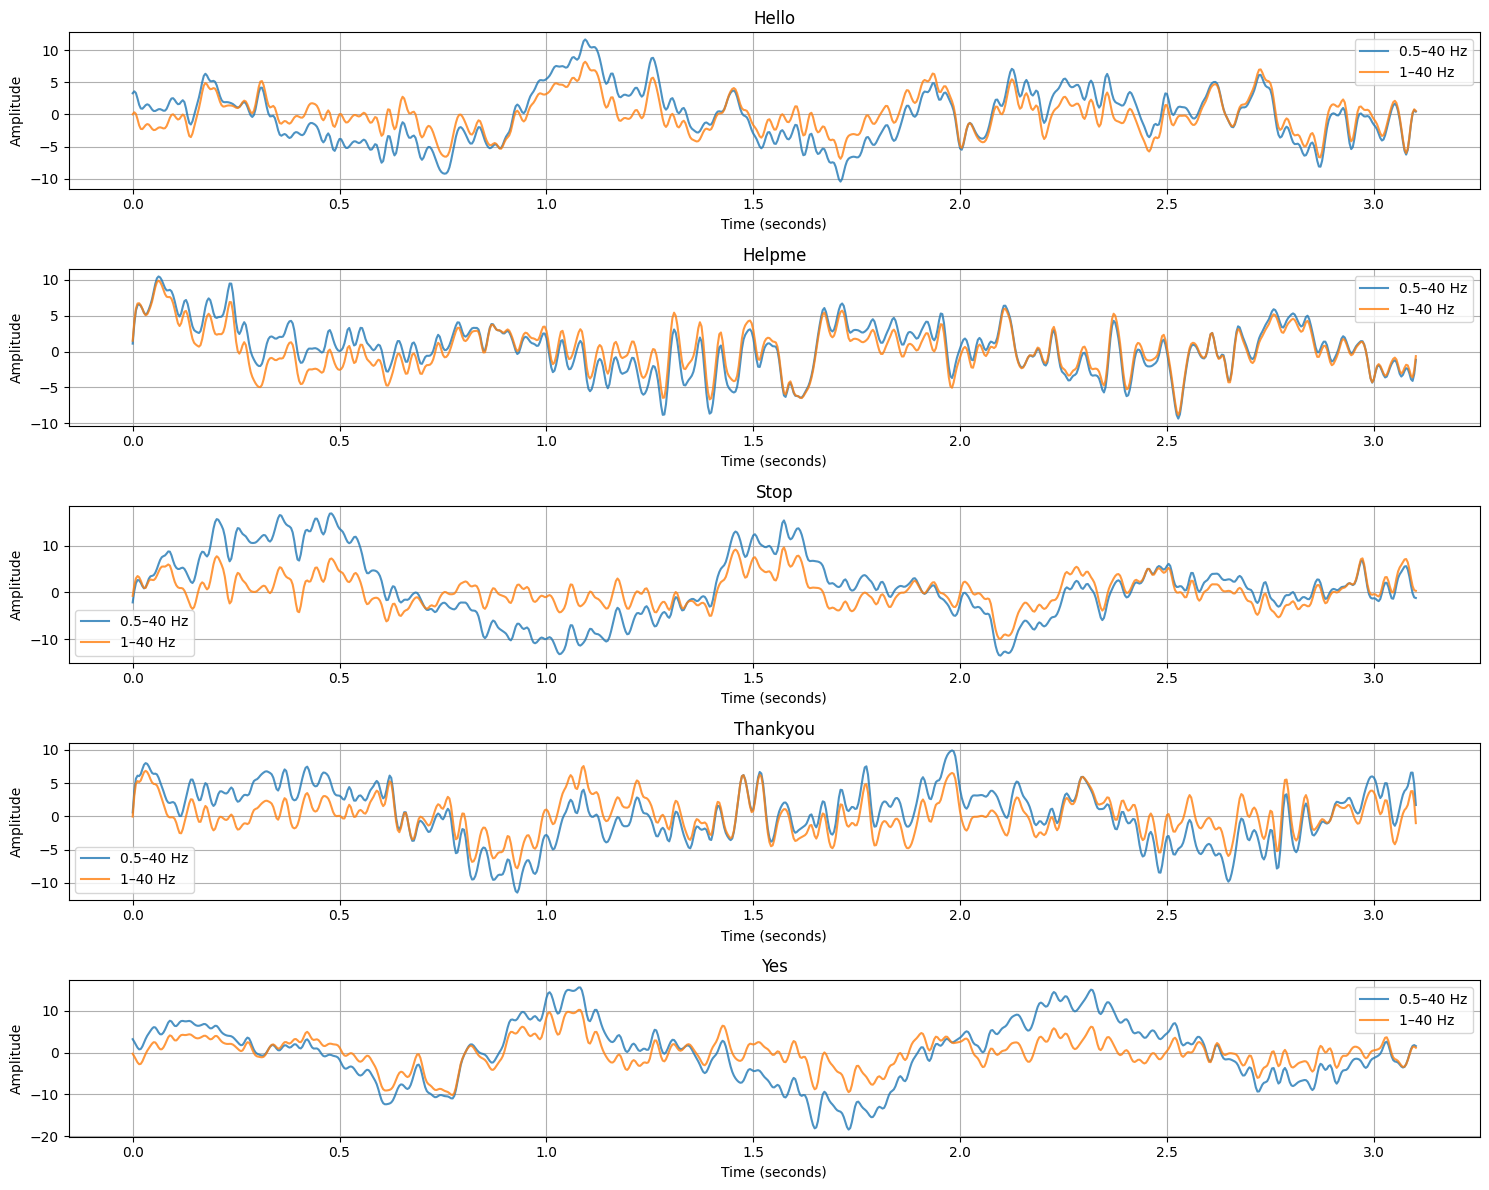

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Select one trial from each class
selected_trials = []

for class_id in range(5):
    trial_index = np.where(class_ids == class_id)[0][0]
    selected_trials.append(trial_index)

time_seconds = np.arange(eeg_cz.shape[1]) / fs

fig, axes = plt.subplots(5, 1, figsize=(15, 12))

for class_id, ax in enumerate(axes):

    trial_index = selected_trials[class_id]

    signal_05 = filtered_signals["0.5_40Hz"][trial_index]
    signal_1 = filtered_signals["1_40Hz"][trial_index]

    ax.plot(
        time_seconds,
        signal_05,
        label="0.5–40 Hz",
        alpha=0.8
    )

    ax.plot(
        time_seconds,
        signal_1,
        label="1–40 Hz",
        alpha=0.8
    )

    ax.set_title(class_names_clean[class_id])
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [24]:
time_seconds = np.asarray(time_values).squeeze() / 1000

print("Start time:", time_seconds[0], "seconds")
print("End time:", time_seconds[-1], "seconds")

Start time: -0.5 seconds
End time: 2.6015625 seconds
